# Saúde e Meio Ambiente - Doenças Cardiovasculares - Data Analysis

## Data Import

In [62]:
import pandas as pd

In [63]:
# Creating main DataFrame
month_dict = {
    "Janeiro": "/01",
    "Fevereiro": "/02",
    "Março": "/03",
    "Abril": "/04",
    "Maio": "/05",
    "Junho": "/06",
    "Julho": "/07",
    "Agosto": "/08",
    "Setembro": "/09",
    "Outubro": "/10",
    "Novembro": "/11",
    "Dezembro": "/12",
}
years = [2020, 2021, 2022, 2023, 2024]
all_datas = []
for year in years:
    for key, value in month_dict.items():
        all_datas.append(f'{year}{value}')
df = pd.DataFrame({'data': all_datas})

In [64]:
# Import Área Queimada
df_list = []
for year in years: 
    path = f'data\Fogo • Mensal por classe • {year}.csv'
    _df = pd.read_csv(path, sep=',', names=['data','Área Queimada'], skiprows=1)
    _df['data'] = _df['data'].map(lambda x: f'{year}{month_dict[x]}')
    df_list.append(_df)
_df = pd.concat(df_list, ignore_index=True)
df = pd.merge(df, _df, on = 'data', how='inner')

In [65]:
# Import Perda de Vegetação
primary_veg_sup = []
secondary_veg_sup = []
for year in years: 
    path = f'data\Perda de Vegetação Nativa • Annual por classe • {year}.csv'
    _df = pd.read_csv(path, sep=',', names=['vegetation','values'], skiprows=1)
    primary_veg_sup+=12*[_df.loc[_df['vegetation'] == 'Primary Vegetation Suppression', 'values'].values[0]]
    secondary_veg_sup+=12*[_df.loc[_df['vegetation'] == 'Secondary Vegetation Suppression', 'values'].values[0]]
_df = pd.DataFrame({
    'data': all_datas,
    'Supressão de Vegetação\n Primária': primary_veg_sup,
    'Supressão de Vegetação\n Secundária': secondary_veg_sup
})
df = pd.merge(df, _df, on = 'data', how='inner')

In [66]:
# Import Déficit de Pressão
_df = pd.read_csv(r'data\Série temporal dos valores - Déficit de pressão de vapor mensal - 1985 - 2024.csv', sep=',').iloc[:, -5:]
press_values = [] 
for column in _df.columns:
    press_values+=list(_df[column])
_df = pd.DataFrame({
    'data': all_datas,
    'Déficit de Pressão': press_values,
})
df = pd.merge(df, _df, on = 'data', how='inner')

In [67]:
# Import Material Particulado MP2.5
# _df = pd.read_csv(r'data\Série temporal dos valores - Material particulado fino mensal (MP2.5) - 2003 - 2024.csv', sep=',').iloc[:, -5:]
# mp2_5_values = [] 
# for column in _df.columns:
#     mp2_5_values+=list(_df[column])
# _df = pd.DataFrame({
#     'data': all_datas,
#     'Material Particulado 2.5': mp2_5_values,
# })
# df = pd.merge(df, _df, on = 'data', how='inner')

In [68]:
# Import Material Particulado MP10
_df = pd.read_csv(r'data\Série temporal dos valores - Material particulado inalável mensal (MP10) - 2003 - 2024.csv', sep=',').iloc[:, -5:]
mp10_values = [] 
for column in _df.columns:
    mp10_values+=list(_df[column])
_df = pd.DataFrame({
    'data': all_datas,
    'Material Particulado $MP_{10}$': mp10_values,
})
df = pd.merge(df, _df, on = 'data', how='inner')

In [69]:
# Import Precipitação Mensal
_df = pd.read_csv(r'data\Série temporal dos valores - Precipitação mensal - 1985 - 2024.csv', sep=',').iloc[:, -5:]
precipitation_values = [] 
for column in _df.columns:
    precipitation_values+=list(_df[column])
_df = pd.DataFrame({
    'data': all_datas,
    'Precipitação': precipitation_values,
})
df = pd.merge(df, _df, on = 'data', how='inner')


In [70]:
# Import Temperatura Mínima Mensal
_df = pd.read_csv(r'data\Série temporal dos valores - Temperatura mínima mensal do ar - 1985 - 2024.csv', sep=',').iloc[:, -5:]
min_temperature_values = [] 
for column in _df.columns:
    min_temperature_values+=list(_df[column])
_df = pd.DataFrame({
    'data': all_datas,
    'Temperatura Mínima': min_temperature_values,
})
df = pd.merge(df, _df, on = 'data', how='inner')


In [71]:
# Import Temperatura Média Mensal
_df = pd.read_csv(r'data\TEMPERATURA MEDIA.csv', sep=',').iloc[:, -5:]
temperature_values = [] 
for column in _df.columns:
    temperature_values+=list(_df[column])
_df = pd.DataFrame({
    'data': all_datas,
    'Temperatura Média': temperature_values,
})
df = pd.merge(df, _df, on = 'data', how='inner')


In [72]:
# Import Temperatura Máxima Mensal
_df = pd.read_csv(r'data\Série temporal dos valores - Temperatura máxima mensal do ar - 1985 - 2024.csv', sep=',').iloc[:, -5:]
max_temperature_values = [] 
for column in _df.columns:
    max_temperature_values+=list(_df[column])
_df = pd.DataFrame({
    'data': all_datas,
    'Temperatura Máxima': max_temperature_values,
})
df = pd.merge(df, _df, on = 'data', how='inner')


In [73]:
# Import Vegetação Urbana
intraurban_veg = []
periurban_veg = []
non_veg = []
for year in years: 
    path = rf'data\Urbano • Vegetação urbana por classe • {year}.csv'
    _df = pd.read_csv(path, sep=',', names=['vegetation_class','values'], skiprows=1)
    # intraurban_veg+=12*[_df.loc[_df['vegetation_class'] == 'Vegetação intraurbana', 'values'].values[0]]
    # periurban_veg+=12*[_df.loc[_df['vegetation_class'] == 'Maciços vegetais urbanos e vegetação periurbana', 'values'].values[0]]
    non_veg+=12*[_df.loc[_df['vegetation_class'] == 'Área urbanizada não vegetada', 'values'].values[0]]
_df = pd.DataFrame({
    'data': all_datas,
    # 'Vegetação Intraurbana': intraurban_veg,
    # 'Vegetação Periurbana': periurban_veg,
    'Área Urbanizada não Vegetada': non_veg,
})
df = pd.merge(df, _df, on = 'data', how='inner')

In [74]:
# Import Umidade Relativa
_df = pd.read_csv(r'data\POWER_Regional_Monthly_2020_2024.csv', sep=',',skiprows=9)


_dfs = []
for column, month_code in zip(_df.columns[4:-1], month_dict.values()):
    __df = _df.groupby('YEAR')[column].mean().reset_index()
    __df['data'] = __df['YEAR'].astype(str) + month_code
    __df = __df.rename(columns={column: 'Umidade Relativa'})
    _dfs.append(__df[['data', 'Umidade Relativa']])
_df = pd.concat(_dfs, ignore_index=True).sort_values('data').reset_index(drop=True)
df = pd.merge(df, _df, on = 'data', how='inner')


In [75]:
# Import Doenças Cardiovasculares - Variável Objetivo
_df = pd.read_csv(r'data\DOENÇAS CARDIOVASCULARES.csv', sep=';', names=['data','Doenças Cardiovasculares'])
df = pd.merge(df, _df, on = 'data', how='inner')

In [76]:
df.head(5)

,data,Área Queimada,Supressão de Vegetação\n Primária,Supressão de Vegetação\n Secundária,Déficit de Pressão,Material Particulado $MP_{10}$,Precipitação,Temperatura Mínima,Temperatura Média,Temperatura Máxima,Área Urbanizada não Vegetada,Umidade Relativa,Doenças Cardiovasculares
0,2020/01,252.007871,13200.376844,12678.339368,0.562242,12.969213,175.261608,14.230184,21.847279,30.536219,208034.332948,75.091270,4449
1,2020/02,36.974182,13200.376844,12678.339368,0.566821,10.092437,145.106407,11.347090,21.056472,31.402467,208034.332948,72.921587,4040
2,2020/03,285.522890,13200.376844,12678.339368,0.727145,9.119052,29.610346,13.085106,21.061717,31.750992,208034.332948,67.610159,3625
3,2020/04,974.315546,13200.376844,12678.339368,0.586596,11.427030,39.705105,7.022974,17.367268,28.170307,208034.332948,68.644286,2908
4,2020/05,1866.347295,13200.376844,12678.339368,0.454817,11.865345,76.485769,4.786183,14.623079,25.208761,208034.332948,72.080794,3247


In [77]:
df.tail(5)

,data,Área Queimada,Supressão de Vegetação\n Primária,Supressão de Vegetação\n Secundária,Déficit de Pressão,Material Particulado $MP_{10}$,Precipitação,Temperatura Mínima,Temperatura Média,Temperatura Máxima,Área Urbanizada não Vegetada,Umidade Relativa,Doenças Cardiovasculares
55,2024/08,8511.036499,11491.602078,13482.641777,0.475509,27.081677,60.230651,0.674019,14.919052,29.216507,221003.31616,80.563651,5586
56,2024/09,6137.335446,11491.602078,13482.641777,0.597615,42.828335,101.779867,7.609460,18.813063,31.804372,221003.31616,81.401746,5333
57,2024/10,495.907366,11491.602078,13482.641777,0.468342,15.941347,169.199291,10.290939,18.966895,31.229660,221003.31616,81.881270,5258
58,2024/11,682.172032,11491.602078,13482.641777,0.476348,10.016061,157.366352,10.471221,20.089398,30.066459,221003.31616,80.341429,3927
59,2024/12,245.096143,11491.602078,13482.641777,0.455806,8.639128,173.522188,13.299861,19.931784,28.533458,221003.31616,79.435238,2063


## Data Exploration and Analysis

In [78]:
from seaborn import pairplot, heatmap, diverging_palette, regplot, boxplot, set_theme
from numpy import zeros_like, triu_indices_from
import matplotlib.pyplot as plt

In [79]:
data_columns = list(df.columns)[1:]
data_columns

['Área Queimada',
 'Supressão de Vegetação\n Primária',
 'Supressão de Vegetação\n Secundária',
 'Déficit de Pressão',
 'Material Particulado $MP_{10}$',
 'Precipitação',
 'Temperatura Mínima',
 'Temperatura Média',
 'Temperatura Máxima',
 'Área Urbanizada não Vegetada',
 'Umidade Relativa',
 'Doenças Cardiovasculares']

In [80]:
len(data_columns)/2

6.0

Text(0.5, 0.98, 'Matriz de Correlação')

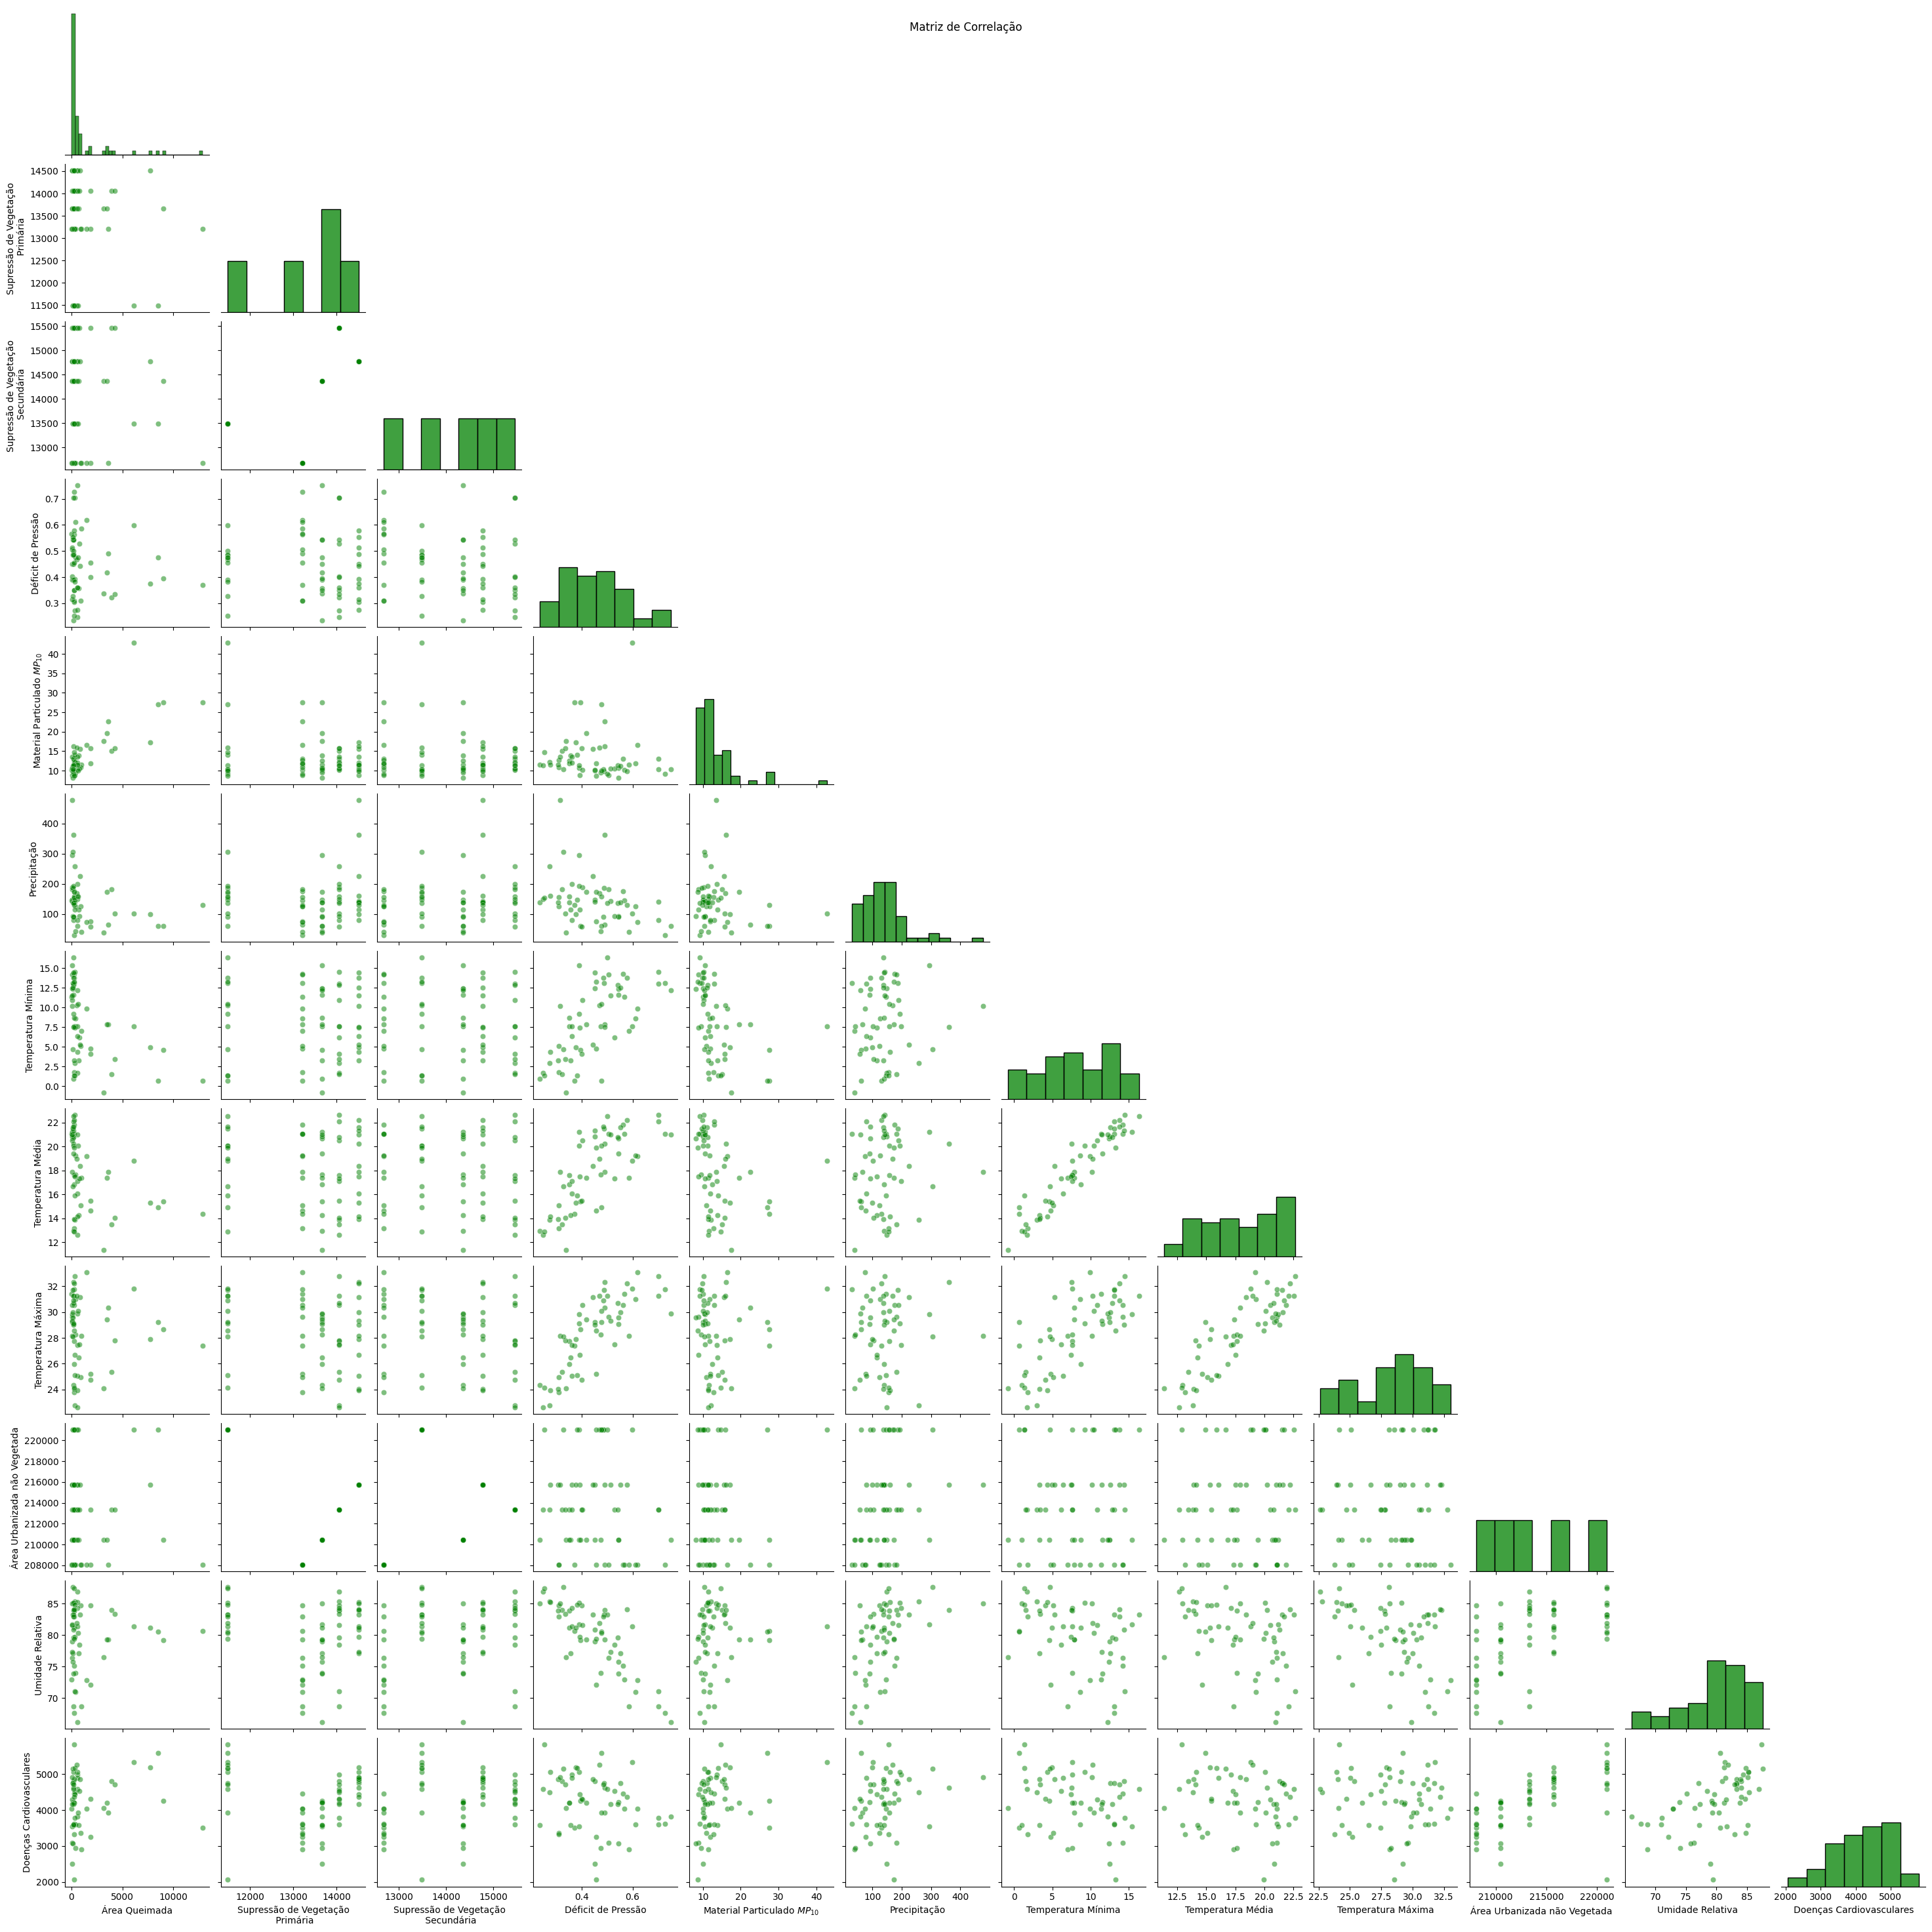

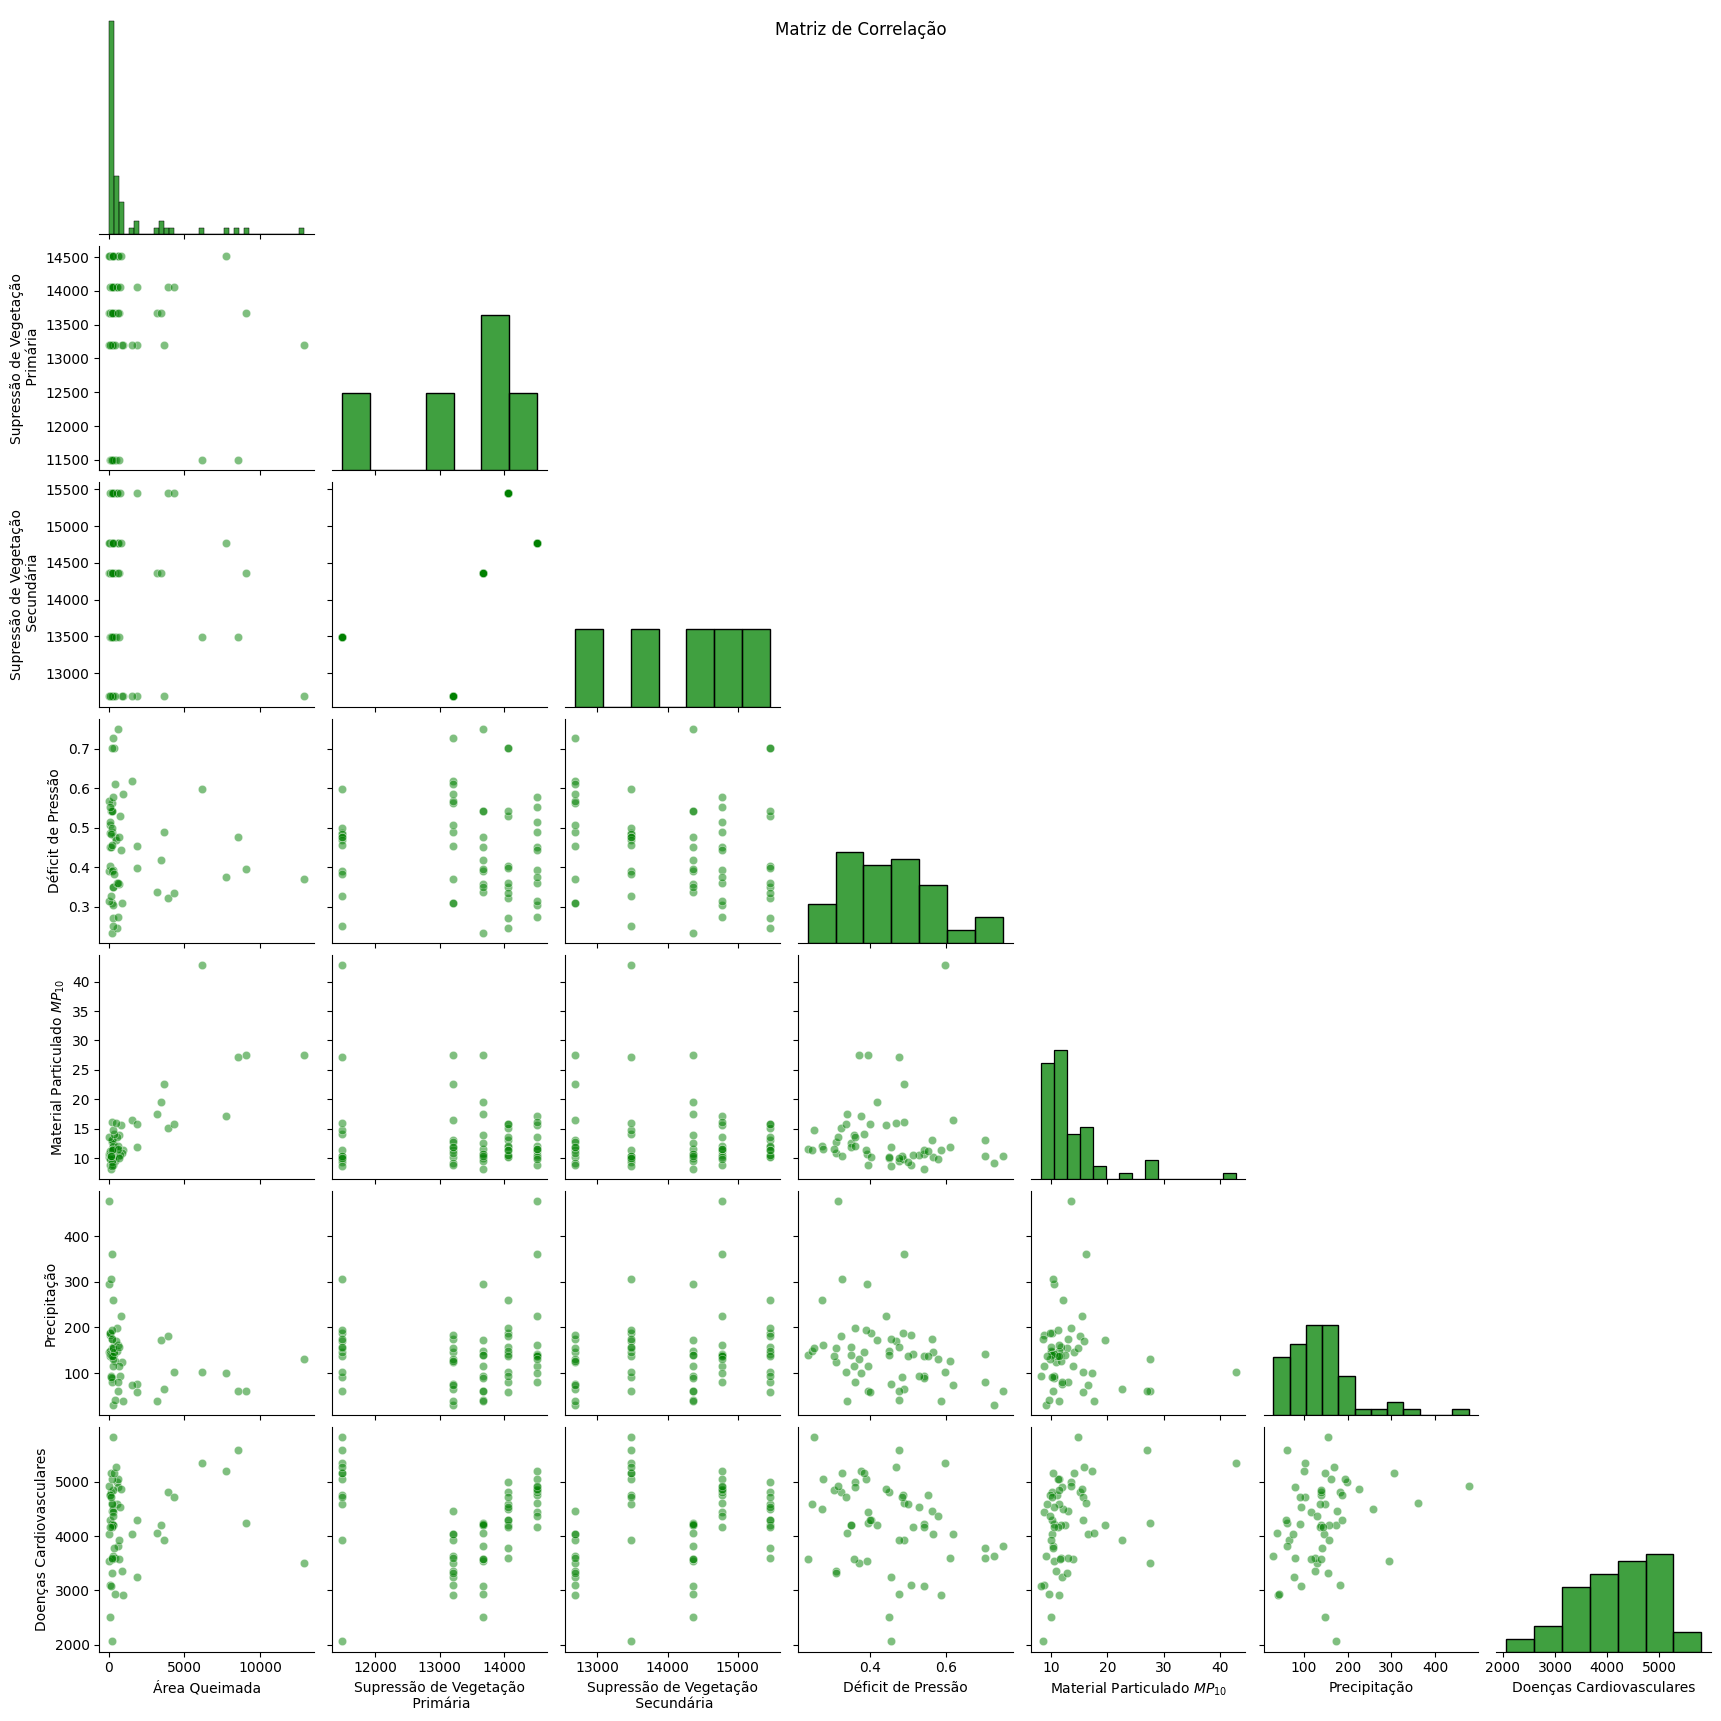

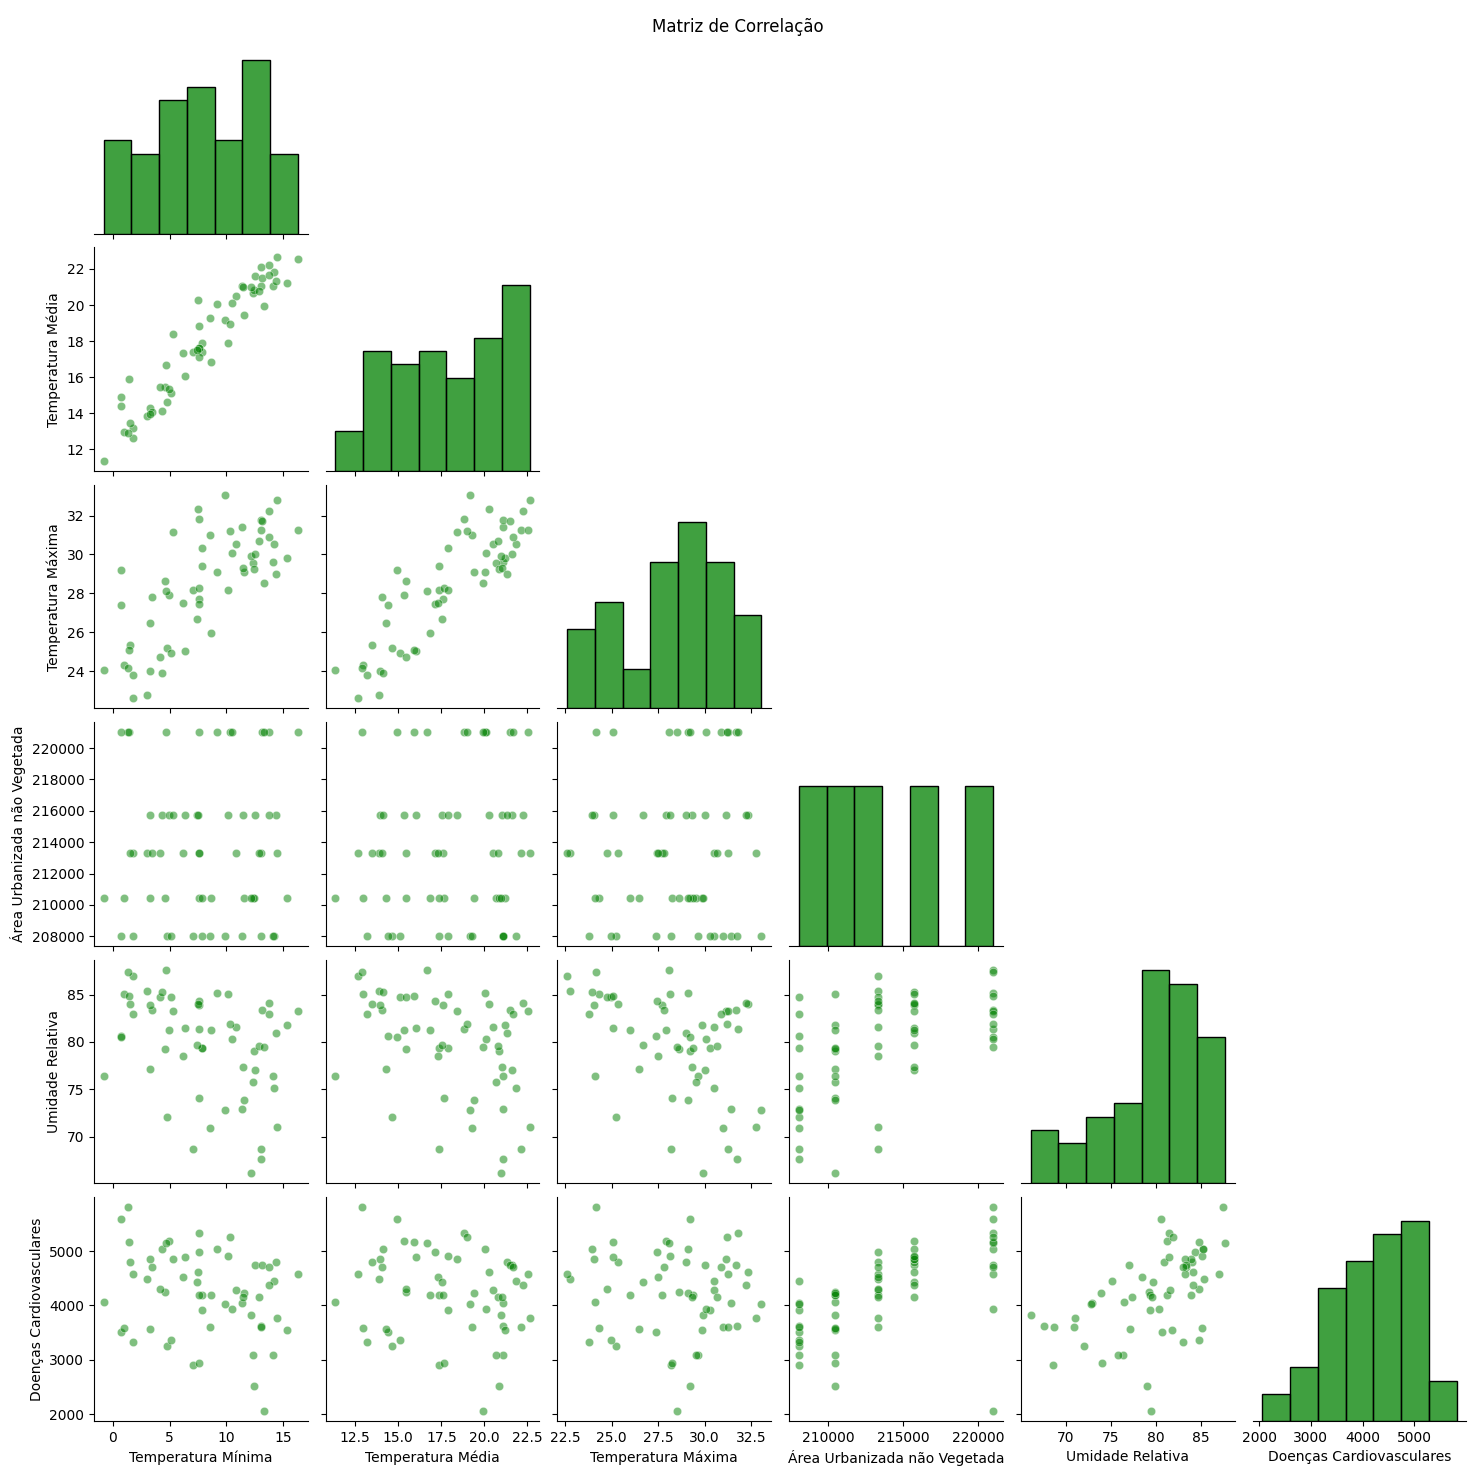

In [81]:
# Correlation Pairplot
pairplot_kws = {
    "plot_kws": {"color": "green", "alpha": 0.5}, 
    "diag_kws": {"color": "green"}
}

pairplot(df[data_columns], corner=True, **pairplot_kws).figure.suptitle('Matriz de Correlação')
pairplot(df[data_columns[:6]+['Doenças Cardiovasculares']], corner=True, **pairplot_kws).figure.suptitle('Matriz de Correlação')
pairplot(df[data_columns[6:]], corner=True, **pairplot_kws).figure.suptitle('Matriz de Correlação')

Text(0.5, 1.0, 'Correlação de Spearman')

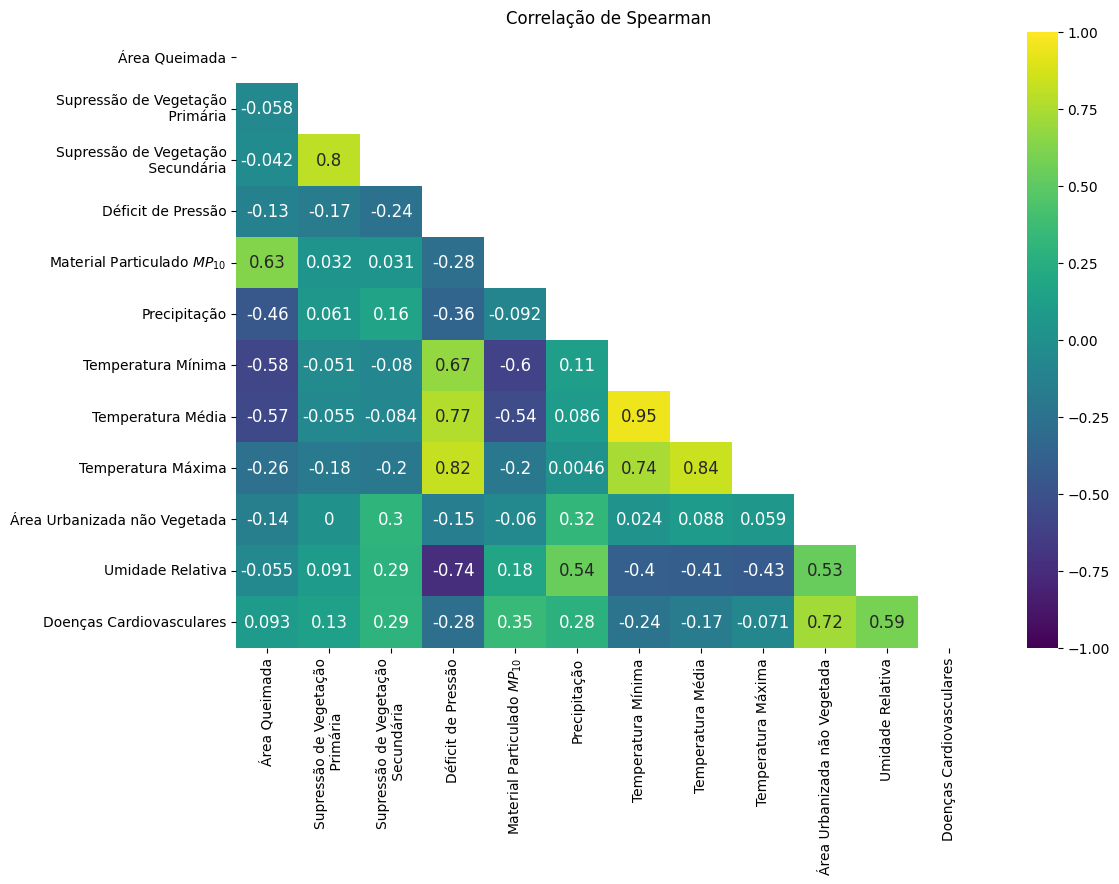

In [82]:
# Correlation Heatmap Spearman
fig, ax = plt.subplots(figsize=(12,8))
corrmat = df[data_columns].corr(method='spearman')
mask= zeros_like(corrmat)
mask[triu_indices_from(mask)] = True
heatmap(corrmat,
            vmax=1, vmin=-1,
            annot=True, annot_kws={'fontsize':12},
            mask=mask,
            # cmap=diverging_palette(20,220,as_cmap=True), ax=ax)
            cmap="viridis")
ax.set_title("Correlação de Spearman")

Text(0.5, 1.0, 'Correlação de Pearson')

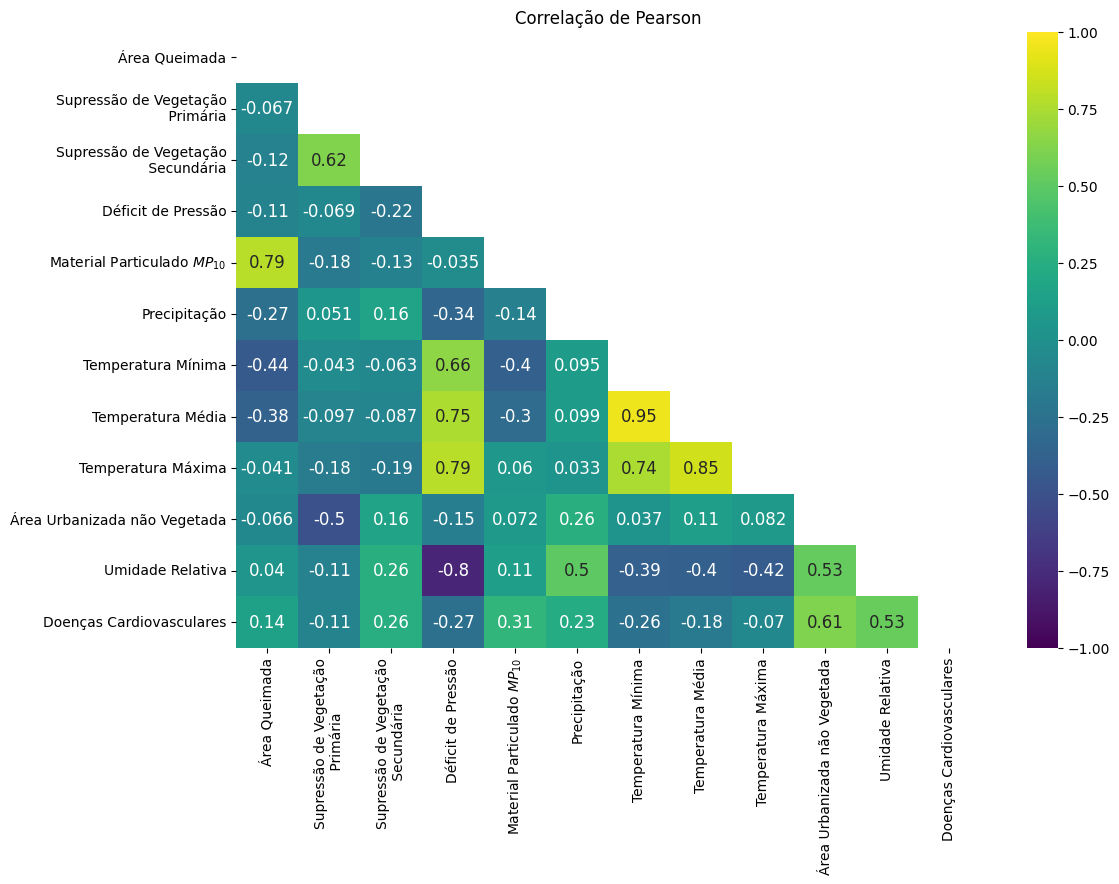

In [83]:
# Correlation Heatmap Pearson
fig, ax = plt.subplots(figsize=(12,8))
corrmat = df[data_columns].corr(method='pearson')
mask= zeros_like(corrmat)
mask[triu_indices_from(mask)] = True
heatmap(corrmat,
            vmax=1, vmin=-1,
            annot=True, annot_kws={'fontsize':12},
            mask=mask,
            # cmap=diverging_palette(20,220,as_cmap=True), ax=ax)
            cmap="viridis")
ax.set_title("Correlação de Pearson")

Text(0.5, 0, 'Material Particulado $MP_{10}$ ($\\mu g/m^3$)')

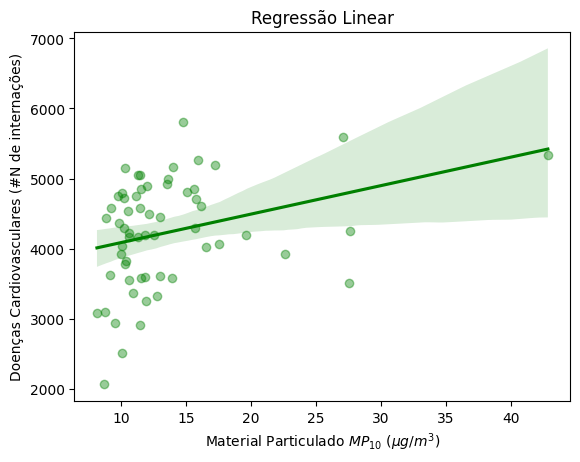

In [85]:
regplot_kws = {
    "scatter_kws": {"color": "green", "alpha": 0.4}, 
    "line_kws": {"color": "green"}
}
# fig, ax = plt.subplots(1, 2, figsize=(14,6))
ax = regplot(x=df['Material Particulado $MP_{10}$'], y=df['Doenças Cardiovasculares'], **regplot_kws)
ax.set_title("Regressão Linear")
ax.set_ylabel('Doenças Cardiovasculares (#N de internações)')
ax.set_xlabel('Material Particulado $MP_{10}$ ($\mu g/m^3$)')

# _df = df[(df['Material Particulado 10'] <= 25)]
# regplot(x=_df['Material Particulado 10'], y=_df['Doenças Cardiovasculares'], **regplot_kws, ax=ax[1])
# ax[1].set_title("Regressão Linear (Sem valores atípicos)")
# ax[1].set_ylabel('Doenças Cardiovasculares (#N de internações)')
# ax[1].set_xlabel('Material Particulado $MP_{10}$ ($\mu g/m^3$)')


Text(0.5, 0, 'Área Urbanizada não Vegetada ($ha$)')

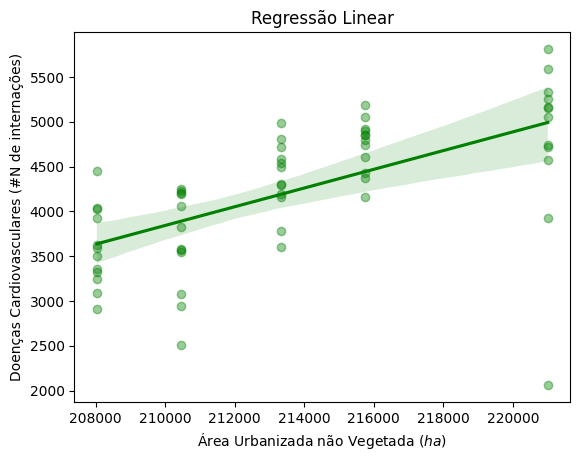

In [ ]:
ax = regplot(x=df['Área Urbanizada não Vegetada'], y=df['Doenças Cardiovasculares'], **regplot_kws)
ax.set_title("Regressão Linear")
ax.set_ylabel('Doenças Cardiovasculares (#N de internações)')
ax.set_xlabel('Área Urbanizada não Vegetada ($ha$)')

Text(0.5, 0, 'Precipitação ($mm$)')

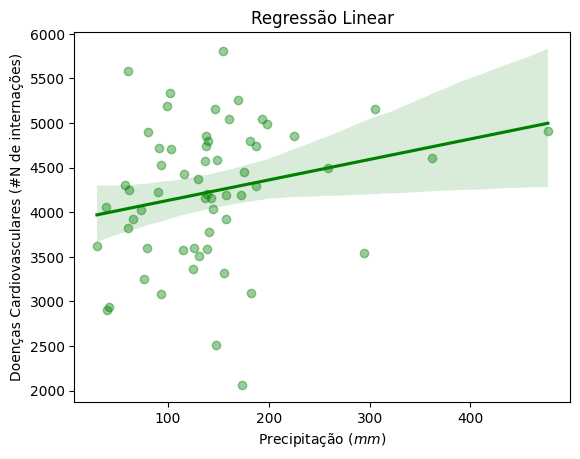

In [ ]:
ax = regplot(x=df['Precipitação'], y=df['Doenças Cardiovasculares'], **regplot_kws)
ax.set_title("Regressão Linear")
ax.set_ylabel('Doenças Cardiovasculares (#N de internações)')
ax.set_xlabel('Precipitação ($mm$)')

Text(0.5, 0, 'Temperatura Média ($C^\\circ$)')

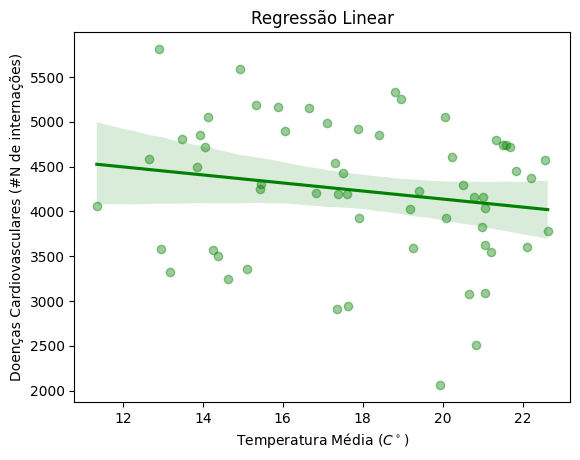

In [ ]:
ax = regplot(x=df['Temperatura Média'], y=df['Doenças Cardiovasculares'], **regplot_kws)
ax.set_title("Regressão Linear")
ax.set_ylabel('Doenças Cardiovasculares (#N de internações)')
ax.set_xlabel(r'Temperatura Média ($C^\circ$)')

Text(0.5, 0, 'Temperatura Mínima ($C^\\circ$)')

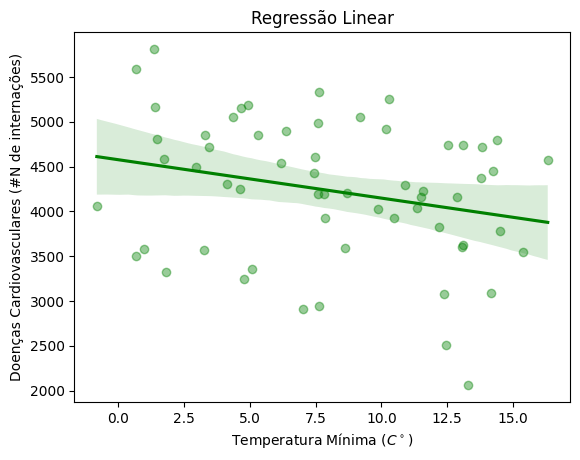

In [ ]:
ax = regplot(x=df['Temperatura Mínima'], y=df['Doenças Cardiovasculares'], **regplot_kws)
ax.set_title("Regressão Linear")
ax.set_ylabel('Doenças Cardiovasculares (#N de internações)')
ax.set_xlabel(r'Temperatura Mínima ($C^\circ$)')

Text(0.5, 0, 'Umidade Relativa ($\\%$)')

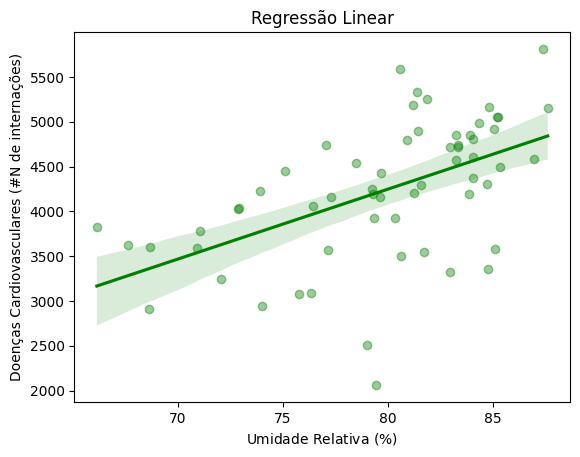

In [ ]:
ax = regplot(x=df['Umidade Relativa'], y=df['Doenças Cardiovasculares'], **regplot_kws)
ax.set_title("Regressão Linear")
ax.set_ylabel('Doenças Cardiovasculares (#N de internações)')
ax.set_xlabel(r'Umidade Relativa ($\%$)')